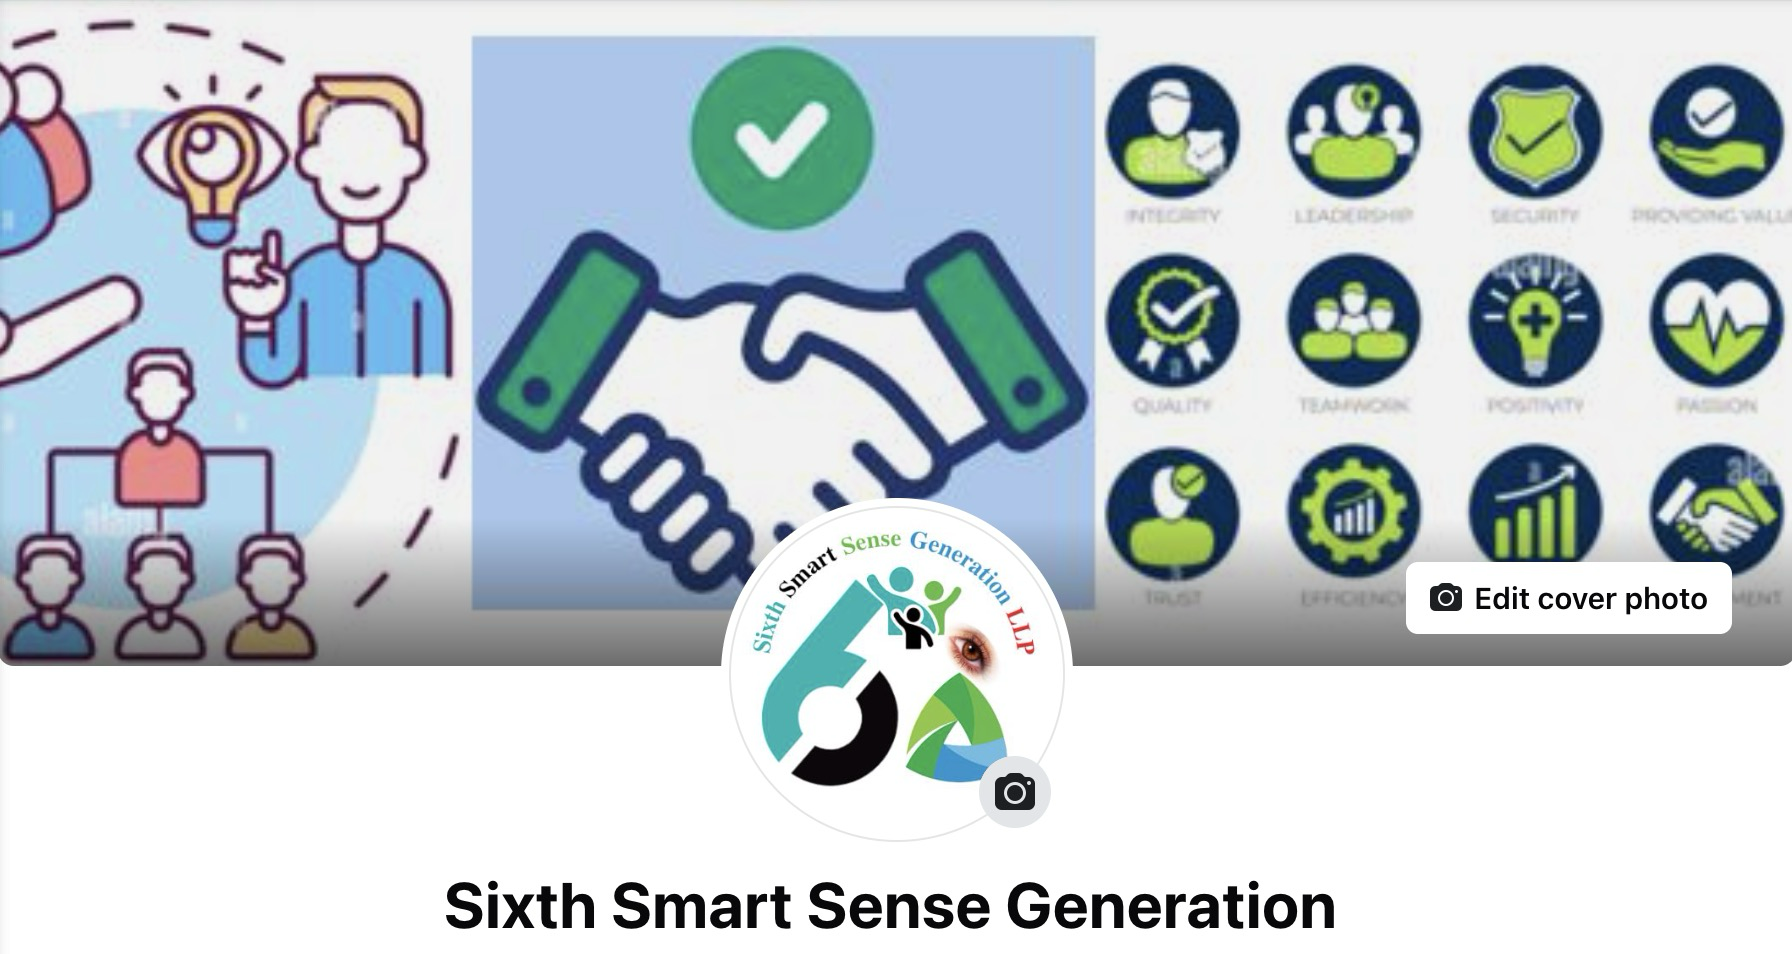

Multi-Agent-Healthcare-iEESBots- Skeleton File

Authors			    :	Kyaw Kyaw Oo, Thar Htet San, <br>
Emails              :   kyaw.consulting@gmail.com, tharhtetsan.ai@gmail.com
Group No			:   Sixth Smart Sense Generation<br>
Started Date        :   Jan 28, 2025<br>
Version             :   1<br>
Released Date    	: 	<br>>
Version             :  2 <br>

CopyRight@2024 by Sixth Smart Sense Generation<br>

Major Medical Services:<br>
Primary Care: Regular check-ups, preventive care, and management of chronic conditions.<br>
Emergency Services: Immediate care for accidents, injuries, and urgent health issues.<br>
Pediatric Care: Health services focused on children, including vaccinations and growth monitoring.<br>
Geriatric Care: Medical care for older adults, addressing age-related conditions.<br>
Mental Health Services: Support for conditions like anxiety, depression, and stress management.<br>
Dental Care: Regular check-ups, cleanings, and treatment of oral health issues.<br>
Optometry: Vision exams, glasses, and treatment for eye conditions.<br>
Pharmacy Services: Access to medications, vaccinations, and prescription management.<br>

Important Health Diagnoses:<br>
Blood Pressure Monitoring: To check for hypertension or hypotension.<br>
Cholesterol Testing: For cardiovascular risk assessment.<br>
Blood Sugar Testing: To monitor for diabetes.<br>
Cancer Screenings: Including mammograms, pap smears, and colonoscopies.<br>
Liver Function Tests: To assess liver health and detect issues like hepatitis.<br>
Kidney Function Tests: Monitoring for signs of kidney disease.<br>
Bone Density Screening: To detect osteoporosis, especially in older adults.<br>
Mental Health Assessments: Diagnosing mental health conditions like depression and anxiety.<br>
Vision and Hearing Tests: To catch early signs of decline in vision or hearing.<br>
Skin Exams: Regular checks for signs of skin cancer.<br>

https://medium.com/the-ai-forum/create-a-multimodal-agent-using-crewai-groq-and-replicate-ai-9e6cef31a20e

### Pls Create Branch Name like dev-your short name
Then we will go for the Staging and Production later 

 ### Verificaiton and Installation of required Python Packages Versions using requirments.txt -> To Do Later

In [ ]:
# manually installation first
# adding -q to suppress output
# %pip install ipykernel -U --user --force-reinstall
# %pip install -qU langchain langchain_community tavily-python langchain-groq groq replicate

# %pip install crewai==0.100.1
# %pip install crewai-tools==0.33.0
# %pip install crewai 'crewai[tools]'
# %pip install -qU crewai crewai-tools

Load all necesssary libraries only once from load_libraries.py to save memory computation cost -> To Do Later

In [18]:
# load basic libraries
import io
import os
from io import BytesIO

import numpy as np
import requests

In [19]:
# load visualization libraries
import matplotlib.pyplot as plt

In [ ]:
# laod environment libraries
from dotenv import load_dotenv

In [ ]:
# laod image libraries
from PIL import Image

In [ ]:
# load audio libraries
from IPython.display import Audio

In [7]:
# load llm packages
from langchain_community.tools.tavily_search import TavilySearchResults

In [25]:
# llm packages
from langchain.agents import tool
from langchain_groq import ChatGroq
from langchain_community.llms import Ollama
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain.chat_models import ChatOpenAI
from langchain_huggingface import *

# from litellm import ChatOpenAI, ChatGPT3, ChatGPT2, ChatDialoGPT

In [57]:
# Loading MultiAgent packages     
import replicate

from crewai import Agent, Task, Crew, Process
from crewai_tools import PDFSearchTool, tool, SerperDevTool, \
                         ScrapeWebsiteTool, \
                         WebsiteSearchTool, \
                         DirectoryReadTool, FileReadTool, SerperDevTool

In [ ]:
# Setup API keys
# input your API keys here
# output: API keys
# function: setup API keys
def setup_api_keys():
    # Load environment variables from the .env file
    load_dotenv()

    # Access specific environment variables
    OPENAI_API_KEY = os.getenv('OPENAI_API_KEY')
    REPLICATE_API_TOKEN = os.getenv('REPLICATE_API_TOKEN')
    TAVILY_API_KEY = os.getenv('TAVILY_API_KEY')
    GROQ_API_KEY = os.getenv('GROQ_API_KEY')
    ANTHROPIC_API_KEY = os.getenv('ANTHROPIC_API_KEY')

    return OPENAI_API_KEY, REPLICATE_API_TOKEN, TAVILY_API_KEY, GROQ_API_KEY, ANTHROPIC_API_KEY

### Location Information -> Image Map(Output)<br>
### Service Fees Inquiry -> Text Information(Output)<br> 
### Diagnosis Processes -> Diagnosis Video(Output)<br> 
### Dental Precaution Procedures -> PDF File(Output)<br>
### Mental Health Gudies -> Audio(Output) <br>

### (In the flow and the rest need to add on) of agent_tools.py 

In [10]:
# Tool for Web Search 
# input: question
# output: response
# function: web search tool
def web_search_tool(question: str) -> str:
    """This tool is useful when we want to search for disease or diagnosis related information."""
    
    # Check if the question contains terms related to diseases or diagnosis
    disease_keywords = ['disease', 'diagnosis', 'symptoms', 'treatment', 'condition', 'health', 'illness']
    
    # If the input contains disease-related keywords, customize the query
    if any(keyword in question.lower() for keyword in disease_keywords):
        question += " related to health or disease"  # Adding context for disease or diagnosis
        
    # Function logic to perform the web search
    # Step 1: Instantiate the Tavily client with your API key
    websearch = TavilySearchResults()
    
    # Step 2: Perform a search query
    response = websearch.invoke({"query": question})
    
    return response

In [ ]:
# Tool for Text to Speech
# input: text
# output: audio
# function: text to speech
def text2speech(text: str) -> str:
    """This tool is useful when we want to convert text to speech, especially for health or diagnosis-related information."""
    
    # Check if the input text is related to disease, diagnosis, or health
    disease_keywords = ['disease', 'diagnosis', 'symptoms', 'treatment', 'condition', 'health', 'illness']
    
    # If disease-related, customize the speech output (e.g., slower pace or clearer tone for medical information)
    if any(keyword in text.lower() for keyword in disease_keywords):
        speech_context = "This text contains health-related information. Please speak clearly and at a moderate pace."
    else:
        speech_context = "General information, please proceed."
    
    # Add the speech context to the input text to guide the output tone or pace
    text = speech_context + " " + text

    # Function logic to convert text to speech
    output = replicate.run(
        "cjwbw/seamless_communication:668a4fec05a887143e5fe8d45df25ec4c794dd43169b9a11562309b2d45873b0",
        input={
            "task_name": "T2ST (Text to Speech translation)",
            "input_text": text,
            "input_text_language": "English",
            "max_input_audio_length": 60,
            "target_language_text_only": "English",
            "target_language_with_speech": "English"
        }
    )
    return output["audio_output"]

In [12]:
# Tool for Text to Image
# input: text
# output: image
# function: text to image
def text2image(text: str) -> str:
    """This tool is useful when we want to generate images from textual descriptions, particularly for disease or diagnosis-related queries."""
    
    # Check if the text contains disease-related terms or medical context
    disease_keywords = ['disease', 'diagnosis', 'symptoms', 'treatment', 'condition', 'health', 'illness', 'medical', 'pathology']
    
    # If disease-related keywords are detected, adjust the prompt to include more medical context
    if any(keyword in text.lower() for keyword in disease_keywords):
        text = "Generate a medical image or diagram related to: " + text
    
    # Function logic to generate image from text
    output = replicate.run(
        "xlabs-ai/flux-dev-controlnet:f2c31c31d81278a91b2447a304dae654c64a5d5a70340fba811bb1cbd41019a2",
        input={
            "steps": 28,
            "prompt": text,
            "lora_url": "",
            "control_type": "depth",
            "control_image": "https://replicate.delivery/pbxt/LUSNInCegT0XwStCCJjXOojSBhPjpk2Pzj5VNjksiP9cER8A/ComfyUI_02172_.png",
            "lora_strength": 1,
            "output_format": "webp",
            "guidance_scale": 2.5,
            "output_quality": 100,
            "negative_prompt": "low quality, ugly, distorted, artefacts",
            "control_strength": 0.45,
            "depth_preprocessor": "DepthAnything",
            "soft_edge_preprocessor": "HED",
            "image_to_image_strength": 0,
            "return_preprocessed_image": False
        }
    )
    print(output)
    return output[0]

In [13]:
## Tool for Image to Text
# input: image
# output: text
# function: image to text
def image2text(image_url: str, prompt: str) -> str:
    """This tool is useful when we want to generate textual descriptions from images, particularly for disease or diagnosis-related content."""
    
    # Check if the prompt contains disease/diagnosis-related terms
    disease_keywords = ['disease', 'diagnosis', 'symptoms', 'treatment', 'condition', 'health', 'illness', 'pathology']
    
    # If disease-related terms are detected, modify the prompt to ensure a medical-focused response
    if any(keyword in prompt.lower() for keyword in disease_keywords):
        prompt = "Describe the medical features, symptoms, and diagnosis-related aspects of this image: " + prompt
    
    # Function logic to generate image description (text) from the image
    output = replicate.run(
        "yorickvp/llava-13b:80537f9eead1a5bfa72d5ac6ea6414379be41d4d4f6679fd776e9535d1eb58bb",
        input={
            "image": image_url,
            "top_p": 1,
            "prompt": prompt,
            "max_tokens": 1024,
            "temperature": 0.2
        }
    )
    
    return "".join(output)


### Setup Router Tool

In [ ]:
# Tool for Router
# input: question
# output: response
# function: router tool
# @tool("router tool")
@tool
def router_tool(question: str) -> str:
    """Router Function for determining the right tool based on input, particularly for disease or diagnosis-related queries."""
    
    # Define disease/diagnosis-related keywords to identify relevant questions
    disease_keywords = ['disease', 'diagnosis', 'symptoms', 'treatment', 'condition', 'health', 'illness', 'pathology', 'medical']
    
    # Check if the question is related to disease/diagnosis
    is_medical_query = any(keyword in question.lower() for keyword in disease_keywords)
    
    # If the question is about health or disease, modify the prompt to reflect this context
    if is_medical_query:
        prompt = f"""Based on the Question below, determine the following:
1. Is the question related to generating an image of a medical condition or diagnosis?
2. Is the question related to describing an image of a medical diagnosis or condition?
3. Is the question related to converting a medical-related text to speech (e.g., describing symptoms)?
4. Is the question a medical-related query that requires web search for more information?

Question: {question, llm}

RESPONSE INSTRUCTIONS:
- Answer either 1 or 2 or 3 or 4.
- Answer should strictly be a string.
- Do not provide any preamble or explanations except for 1 or 2 or 3 or 4.

OUTPUT FORMAT:
1
"""
    else:
        # Otherwise, use the original prompt for generic queries
        prompt = f"""Based on the Question below, determine the following:
1. Is the question directed at generating image?
2. Is the question directed at describing the image?
3. Is the question directed at converting text to speech?
4. Is the question a generic one and needs to be answered searching the web?

Question: {question}

RESPONSE INSTRUCTIONS:
- Answer either 1 or 2 or 3 or 4.
- Answer should strictly be a string.
- Do not provide any preamble or explanations except for 1 or 2 or 3 or 4.

OUTPUT FORMAT:
1
"""
    
    # Invoke the LLM with the adjusted prompt
    response = llm.invoke(prompt).content
    
    # Return the appropriate function based on the response
    if response == "1":
        return 'text2image'
    elif response == "3":
        return 'text2speech'
    elif response == "4":
        return 'web_search'
    elif 'self-attention' in question:
        return 'vectorstore'
    else:
        return 'web-search'

### Setup Retriever Tool

In [16]:
# retriver tool
# input: router_response, question, image_url
# output: response
# function: retriver tool
@tool
def retriver_tool(router_response:str,question:str,image_url:str) -> str:
  """Retriver Function"""
  if router_response == 'text2image':
    return text2image(question)
  elif router_response == 'text2speech':
    return text2speech(question)
  elif router_response == 'image2text':
    return image2text(image_url,question)
  else:
    return web_search_tool(question)

### Setup the LLM -> lm_models.py

In [59]:
#  llm models
# input: model_type
# output: model
# function: llm models
def llm_models(model_type: str):
    """Function to select and return the appropriate LLM based on model_type."""
    
    # Base parameters for models
    base_params = {
        "temperature": 0.1,
        "max_tokens": 1000
    }
    
    # Selection logic for different models
    if model_type == "llama3-8b-8192":
        # ChatOpenAI model for Llama 3 8B model
        return ChatOpenAI(
            openai_api_key=setup_api_keys()[3],
            openai_api_base="https://api.groq.com/openai/v1",
            model_name="llama3-8b-8192",
            **base_params
        )
    elif model_type == "llama-3.2-1b-preview":
        # ChatOpenAI model for Llama 3 1B model
        return ChatOpenAI(
            openai_api_key=setup_api_keys()[3],
            openai_api_base="https://api.groq.com/openai/v1",
            model_name="llama-3.2-1b-preview",
            **base_params
        )
    elif model_type == "huggingface/starcoder":
        # HuggingFace model for Starcoder
        return ChatOpenAI(
            completion_provider='huggingface',
            model='huggingface/starcoder',
            temperature=0.7  # Different temperature for this model
        )
    elif model_type == "groq-llama-3.1-70b-versatile":
        # ChatGroq model for Groq Llama 3.1
        return ChatGroq(
            model_name="llama-3.1-70b-versatile",
            **base_params
        )
    elif model_type == "ollama-llama3.2":
        # Ollama model for Llama 3.2
        return Ollama(
            model="llama3.2:latest",
            **base_params
        )
    else:
        raise ValueError("Invalid model type specified.")
    
    return model

# Example of using the function
model_type = "llama3-8b-8192"
llm_model = llm_models(model_type)

ValidationError: 1 validation error for ChatOpenAI
__root__
  Did not find openai_api_key, please add an environment variable `OPENAI_API_KEY` which contains it, or pass `openai_api_key` as a named parameter. (type=value_error)

### Setup the Router, Retriever Agent

In [ ]:
# setup router, retriver agents   
# input: llm, router_tool
# output: Router_Agent, Retriever_Agent
# function: setup agents
def setup_agents(llm, router_tool):
    """Setup the Router Agent with the specified LLM and Router Tool, with a focus on disease diagnosis and medical queries."""
    
    # Define the Router Agent with the specified LLM and Router Tool for medical diagnosis
    Router_Agent = Agent(
        role='Router',
        goal='Route user medical or diagnostic queries to the appropriate tool such as image generation, text-to-speech, or web search.',
        backstory=(
            "You are an expert at routing user queries related to medical conditions and disease diagnosis. "
            "Use the text to image tool to generate medical images based on textual descriptions, including diagnostic imagery such as radiographs, CT scans, or dermatological conditions. "
            "Use the text to speech tool to convert detailed medical descriptions, such as symptoms or diagnostic information, into spoken words for better understanding. "
            "Use the image-to-text tool to interpret medical images, such as x-rays, MRI scans, or patient symptom charts, into descriptive text for diagnosis assistance. "
            "Use the web search tool to gather current information about diseases, treatments, or medical conditions that may relate to the user's query. "
            "When a query contains keywords related to disease or diagnosis, route the user to the relevant tool for a detailed response. "
            "For example, if a question concerns medical symptoms, direct it to text-to-speech to explain those symptoms or suggest next steps, or if it's about disease identification, route it to medical image generation or search for information on conditions and treatments."
        ),
        verbose=True,
        allow_delegation=False,
        llm=llm,  # Ensure llm is properly initialized
        tools=[router_tool],  # Ensure router_tool is properly set
    )

    # Define the Retriever Agent to process the query responses
    Retriever_Agent = Agent(
        role="Retriever",
        goal="Utilize the information gathered from the Router to answer the medical question and retrieve relevant image or data.",
        backstory=(
            "You assist in processing medical queries and directing tasks to respective agents, following the Router's guidance."
            "After receiving a response from the Router, you perform the necessary task, whether it's answering a question or providing a medical image URL."
            "You do not offer additional explanations but instead directly assist with processing the task provided by the Router."
        ),
        verbose=True,
        allow_delegation=False,
        llm=llm,
        tools=[retriver_tool],
    )

    return Router_Agent, Retriever_Agent

### Setup the Retriever Agent

### Setup the Router Task

In [ ]:
# setup tasks   
# input: Router_Agent
# output: router_task
# function: setup tasks
def setup_tasks(Router_Agent, Retriever_Agent):
    router_task = Task(
        description=("Analyze the keywords in the question {question} related to disease diagnosis or medical symptoms. "
                     "If the question {question} instructs to describe a medical image, use the image URL {image_url} to generate a detailed and high-quality image, covering all the nuances described in the textual descriptions, such as medical conditions or anatomy. "
                     "Based on the keywords, decide whether it is eligible for generating a medical image (text2image), converting text to speech for symptoms or diagnosis (text2speech), or performing a web search for disease information. "
                     "Return a single word 'text2image' if it is eligible for generating images from textual descriptions of medical conditions or anatomy. "
                     "Return a single word 'text2speech' if it is eligible for converting text to speech related to medical symptoms or conditions. "
                     "Return a single word 'image2text' if it is eligible for describing the medical image based on the question {question} and image URL {image_url}. "
                     "Return a single word 'web_search' if it is eligible for searching for disease-related information or medical conditions. "
                     "Do not provide any other preamble or explanation."),
        expected_output=("Give a choice 'web_search' or 'text2image' or 'text2speech' or 'image2text' based on the question {question} and image URL {image_url}. "
                         "Do not provide any preamble or explanations except for 'text2image' or 'text2speech' or 'web_search' or 'image2text'."),
        agent=Router_Agent,
    )

    retriever_task = Task(
        description=("Based on the response from the 'router_task', generate a response for the question {question} with the help of the respective tool. "
                     "Use the web_search_tool to retrieve current information from the web in case the router task output is 'web_search', specifically related to diseases, treatments, or symptoms. "
                     "Use the text2speech tool to convert the text about symptoms or medical information to speech in English in case the router task output is 'text2speech'. "
                     "Use the text2image tool to generate detailed and high-quality images depicting medical conditions or anatomical descriptions in case the router task output is 'text2image'. "
                     "Use the image2text tool to describe medical images, such as x-rays, MRIs, or diagnostic images, based on the question {question} and the image URL {image_url}, in case the router task output is 'image2text'."),
        expected_output=("You should analyze the output of the 'router_task'. "
                         "If the response is 'web_search', use the web_search_tool to retrieve information from the web related to diseases or medical conditions. "
                         "If the response is 'text2image', use the text2image tool to generate a detailed and high-quality image covering all the nuances described in the textual descriptions related to medical conditions. "
                         "If the response is 'text2speech', use the text2speech tool to convert the text in the question {question} to speech, explaining medical symptoms or conditions. "
                         "If the response is 'image2text', use the 'image2text' tool to describe the medical image based on the question {question} and the image URL {image_url}."),
        agent=Retriever_Agent,
        context=[router_task],
    )

    return router_task, retriever_task

### Setup the Retriever Task

### Setup the Crew

In [ ]:
# create crew
# input: Router_Agent, Retriever_Agent, router_task, retriever_task
# output: crew
# function: create crew
def setup_crew():  # model type, router_tool
    """Setup the Crew with the Router and Retriever Agents, along with their respective tasks."""
    
    # Load the LLM model based on the specified model type
    model_type = "llama3-8b-8192"
    llm = llm_models(model_type)
    Router_Agent, Retriever_Agent = setup_agents(llm, router_tool)
    router_task, retriever_task = setup_tasks(Router_Agent, Retriever_Agent)

    crew = Crew(
        agents=[Router_Agent,Retriever_Agent],
        tasks=[router_task,retriever_task],
        verbose=True,
        memory=True
    )

    return crew

2025-02-14 22:25:05,037 - 8469319488 - __init__.py-__init__:537 - WARNING: Overriding of current TracerProvider is not allowed


### Image Generation Task <br>
kickoff the crew

In [ ]:
#  run crew
# input:
# output: result
# function: run crew
def run_crew(inputs):
    crew = setup_crew()
    
    result = crew.kickoff(inputs=inputs)
    return result

inputs = {
        "question": "Generate a detailed image based upon this text: a close-up medical image of a patient’s skin showing early symptoms of melanoma, with clear contrast, sharp lighting to highlight irregularities in the skin surface, and a focus on the affected area.",
        "image_url": " "
    }

In [108]:
# result.raw

### Display the Image Generated

In [ ]:
# generate image
# input: result
# output: image
# function: generate image
def generate_image(result, image_url):
    # URL of the image
    result = run_crew()
    # image_url = result.raw
    image_url = result

    # Fetch the image
    response = requests.get(image_url)

    # Check if the request was successful
    if response.status_code == 200:
        # Open the image using PIL
        img = Image.open(BytesIO(response.content))

        # Display the image using matplotlib
        plt.imshow(img)
        plt.axis('off')  # Hide the axis
        plt.show()
    else:
        print("Failed to retrieve image. Status code:", response.status_code)


In [ ]:
# run crew
def run_crew():
    crew = setup_crew(inputs)
    
    result = crew.kickoff(inputs=inputs)
    return result

inputs ={"question":"Provide a detailed description.","image_url":"https://images.unsplash.com/photo-1470770903676-69b98201ea1c?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=1740&q=80.jpg"}

In [ ]:
# generate image
# input: result
# output: image
# function: generate image
def generate_image(result, image_url):
    # URL of the image
    result = run_crew()
    # image_url = result.raw
    image_url = result

    # Fetch the image
    response = requests.get(image_url)

    # Check if the request was successful
    if response.status_code == 200:
        # Open the image using PIL
        img = Image.open(BytesIO(response.content))

        # Display the image using matplotlib
        plt.imshow(img)
        plt.axis('off')  # Hide the axis
        plt.show()
    else:
        print("Failed to retrieve image. Status code:", response.status_code)

# URL of the image
image_url = "https://images.unsplash.com/photo-1470770903676-69b98201ea1c?ixlib=rb-4.0.3&ixid=MnwxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8&auto=format&fit=crop&w=1740&q=80.jpg"

### Kick off the Crew for Speech Generation

In [ ]:
# run crew
#input:
#output: result
#function: run crew
def run_crew(inputs_speech):
    crew = setup_crew()
    
    result = crew.kickoff(inputs=inputs_speech)

    return result

inputs_speech = {
        "question": "Generate a speech for this text: The patient presents with a dry cough, shortness of breath, and mild chest pain. These symptoms may indicate a respiratory condition, possibly pneumonia or bronchitis. Further medical evaluation is recommended.",
        "image_url": " "
    }

In [ ]:
# result.raw


### Play the Audio


In [ ]:
# generate audio
#input: result
#output: audio
#function: generate audio
def generate_audio(result):
    result = run_crew()  # Run the crew with the medical diagnosis-related inputs
    
    # URL of the audio file generated from the crew
    audio_url = result.raw
    
    # Play the audio file explaining the disease diagnosis or symptoms
    Audio(audio_url, autoplay=True)

# Call the function to play the diagnosis audio
# generate_audio()

### Kickoff the Crew to present results from the web

In [ ]:
# run_diagnosis_crew
# input:
# output: result
# function: run diagnosis crew
def run_diagnosis_crew(inputs):
    crew = setup_crew()
  
    result = crew.kickoff(inputs=inputs)

    return result

inputs = {"symptoms":"fever, cough, fatigue", "patient_history":" "}

In [116]:
# result.raw

In [ ]:
# download_medical_diagnosis_paper
# input:
# output: result
# function: download medical diagnosis paper
def download_medical_diagnosis_paper(pdf_url ):
    
    # Send a GET request to download the PDF
    response = requests.get(pdf_url)
    
    # Save the PDF to a local file
    with open('medical_diagnosis_paper.pdf', 'wb') as file:
        file.write(response.content)
    
    return "Paper downloaded successfully"

# Sample URL for a medical diagnosis paper (can be replaced with a real medical paper link)
pdf_url = 'https://proceedings.neurips.cc/paper_files/paper/2017/file/3f5ee243547dee91fbd053c1c4a845aa-Paper.pdf'

# Example of calling the function
result = download_medical_diagnosis_paper(pdf_url)
print(result)

In [ ]:
# setup_rag_tool
# input: pdf_fiel
# output: rag_tool
# function: setup rag tool -> Create a RAG tool variable to pass our PDF
def setup_rag_tool(pdf_fiel):
    rag_tool = PDFSearchTool(pdf=pdf_fiel,
        config=dict(
            llm=dict(
                provider="groq", # or google, openai, anthropic, llama2, ...
                config=dict(
                    model="llama3-8b-8192",
                    # temperature=0.5,
                    # top_p=1,
                    # stream=true,
                ),
            ),
            embedder=dict(
                provider="huggingface", # or openai, ollama, ...
                config=dict(
                    model="BAAI/bge-small-en-v1.5",
                    #task_type="retrieval_document",
                    # title="Embeddings",
                ),
            ),
        )
    )
    return rag_tool

pdf_fiel='medical_diagnosis_paper.pdf'
rag_tool = setup_rag_tool(pdf_fiel)

In [ ]:
# run_diagnosis_rag_tool
# input: symptoms
# output: result
# function: run diagnosis rag tool
def run_diagnosis_rag_tool(symptoms):
    # Assuming rag_tool is a medical diagnosis tool that uses symptoms to provide a diagnosis
    result = rag_tool.run(symptoms)
    return result

# Example of calling the function with a symptoms-related question
symptoms_query = "What could be the possible diagnosis for fever, cough, and difficulty breathing?"
result = run_diagnosis_rag_tool(symptoms_query)
print(result)

Using Tool: Search a PDF's content
Relevant Content:
makes it more difﬁcult to learn dependencies between distant positions [ 11]. In the Transformer this is reduced to a constant number of operations, albeit at the cost of reduced effective resolution due to averaging attention-weighted positions, an effect we counteract with Multi-Head Attention as described in section 3.2. Self-attention, sometimes called intra-attention is an attention mechanism relating different positions of a single sequence in order to compute a representation of the sequence. Self-attention has been used successfully in a variety of tasks including reading comprehension, abstractive summarization, textual entailment and learning task-independent sentence representations [4, 22, 23, 19]. End-to-end memory networks are based on a recurrent attention mechanism instead of sequence- aligned recurrence and have been shown to perform well on simple-language question answering and language modeling tasks [28]. To the 

In [ ]:
# search_diagnosis_info
# input: symptoms
# output: search_results
# function: search diagnosis info -> diagnosis-related information using Tavily API (or DuckDuckGo)
def search_diagnosis_info(symptoms):
    # Using TavilySearchResults (or DuckDuckGo equivalent) to fetch medical search results
    web_search_tool = TavilySearchResults(k=3)  # Fetching top 3 results
    
    # Search for relevant diagnosis information based on symptoms
    search_results = web_search_tool.search(symptoms)
    
    return search_results

# Example of calling the function with symptoms-related query
symptoms_query = "What could cause headache, nausea, and dizziness?"
result = search_diagnosis_info(symptoms_query)
print(result)

In [ ]:
# run_diagnosis_search
# input: symptoms_or_condition
# output: search_results
# function: run diagnosis search -> medical diagnosis search query using the web search tool
def run_diagnosis_search(symptoms_or_condition):
    # Use the web search tool to search for relevant diagnosis or condition information
    search_results = web_search_tool.run(symptoms_or_condition)
    return search_results

# Example of calling the function with a medical symptoms-related query
symptoms_query = "What could cause chest pain, shortness of breath, and dizziness?"
result = run_diagnosis_search(symptoms_query)
print(result)

[{'url': 'https://medium.com/@frankmorales_91352/the-evolution-and-impact-of-attention-mechanisms-in-large-language-models-338dbdd0d2ff',
  'content': 'This paper explores the evolution of attention mechanisms, from their early roots in addressing limitations of recurrent neural networks (RNNs) to the development of self-attention and its profound impact on the field of AI, particularly in the rise of large language models (LLMs) like GPT-4, Deepseek-R1, Mistral-7b, LLaMA, BERT, Claude, and Gemini. The self-attention mechanism has been particularly influential in the development of LLMs. By allowing models to weigh the importance of different words in a sequence and capture long-range dependencies, self-attention has enabled LLMs to generate coherent and contextually relevant text. Attention mechanisms have revolutionized the field of NLP and have been instrumental in developing powerful LLMs. Self-attention, in particular, has enabled models to capture long-range dependencies and cont

In [ ]:
# diagnosis_agent
# input: llm
# output: Router_Agent        
# function: diagnosis agent -> Agent for routing medical diagnosis-related questions to appropriate resources
def diagnosis_agent(llm):
    # Agent for routing medical diagnosis-related questions to appropriate resources
    Router_Agent = Agent(
    role='Diagnosis Router',
    goal='Route user symptoms or diagnosis-related questions to a medical knowledge base or web search',
    backstory=(
        "You are an expert at routing a user's medical symptoms or diagnosis-related questions."
        "Use the medical knowledge base for questions regarding known conditions, treatments, or symptoms."
        "If the question is more general or outside the scope of the knowledge base, route it to a web search for up-to-date medical information."
    ),
    verbose=True,
    allow_delegation=False,
    llm=llm,
    )

    return Router_Agent
    

In [ ]:
# diagnosis_task
# input: Router_Agent
# output: diagnosis_task
# function: diagnosis task -> Task for diagnosing medical symptoms or conditions
def diagnosis_task(Router_Agent):
    # Task for diagnosing medical symptoms or conditions
    diagnosis_task = Task(
    description=("Analyze the symptoms or condition {symptoms_or_condition} to determine the appropriate response."
                 "If the symptoms or condition {symptoms_or_condition} are known and can be diagnosed, use the medical knowledge base to provide a detailed diagnosis."
                 "If the symptoms or condition {symptoms_or_condition} are general or unknown, use a web search to find relevant medical information."),
    expected_output=("Provide a detailed diagnosis or medical information based on the symptoms or condition {symptoms_or_condition}."
                     "Use the medical knowledge base for known conditions or a web search for general or unknown conditions."),
    agent=Router_Agent,
    tools=[router_tool],
    )

    return diagnosis_task


In [ ]:
# location_information_agent
# input: llm
# output: Location_Retriever_Agent
# function: location information agent -> Agent for retrieving location-related information 
def location_information_agent(llm):
    # Agent for retrieving location-related information
    Location_Retriever_Agent = Agent(
    role="Location Retriever",
    goal="Use the information retrieved from location databases or web search to answer the question",
    backstory=(
        "You are an assistant for answering location-related questions."
        "Use the information from location databases or online sources to provide answers regarding places, landmarks, businesses, or geographical features."
        "Ensure the answer is clear, concise, and relevant to the user's location query."
    ),
    verbose=True,
    allow_delegation=False,
    llm=llm,
    )

    return Location_Retriever_Agent

In [ ]:
# location_router_task
# input: question
# output: location_retriever_task
# function: location router task -> Task for retrieving location-related information based on the router's response
def location_router_task(question, Location_Retriever_Agent):
    # Task for retrieving location-related information based on the router's response
    location_retriever_task = Task(
        description=(
            "Based on the response from the location router task, extract location-related information for the question {question} "
            "with the help of the respective tool. Use the web_search_tool to retrieve location data from the web in case the router task output is 'websearch'. "
            "Use the location_rag_tool to retrieve location-specific information from the vectorstore in case the router task output is 'vectorstore'."
        ),
        expected_output=(
            "You should analyze the output of the 'location_router_task'. "
            "If the response is 'websearch', use the web_search_tool to retrieve location-related information from the web. "
            "If the response is 'vectorstore', use the location_rag_tool to retrieve location-specific information from the vectorstore. "
            "Return a clear and concise text response with relevant location details."
        ),
        agent=Location_Retriever_Agent,
        context=[location_router_task],
        #tools=[location_retriever_tool],  # Tool that can be used to retrieve location-based data (if necessary)
    )

    return  location_retriever_task

In [ ]:
# precaution_agent
# input: llm
# output: Dental_Precaution_Agent
# function: precaution agent -> Agent for Dental Precaution Procedures
def precaution_agent(llm):
    # Agent for Dental Precaution Procedures
    precaution_agent = Agent(
        role='Dental Precaution Grader',
        goal='Filter out irrelevant dental precaution advice',
        backstory=(
            "You are a grader assessing the relevance of a document regarding dental health precautions."
            "If the document contains key dental precaution terms such as brushing, flossing, oral hygiene, "
            "dental check-up, or other relevant dental health keywords, grade it as relevant."
            "The goal is to ensure that the response provides useful information related to dental care practices, "
            "such as brushing techniques, flossing, or other preventive measures to maintain oral health."
        ),
        verbose=True,
        allow_delegation=False,
        llm=llm,
    )
    return precaution_agent


In [ ]:
# precaution_task
# input: precaution_agent, retriever_task
# output: precaution_task_task
# function: precaution task -> Task for Dental Precaution Procedures
def precaution_task(pecaution_agent, retriever_task):
    # Task 3 for Dental Precaution Procedures
    precaution_task_task = Task(
        description=(
            "Based on the response from the retriever task for the question '{question}', evaluate whether "
            "the retrieved content is relevant to dental precaution procedures."
            "Look for key dental terms such as brushing, flossing, oral hygiene, dental check-ups, or other relevant dental care practices."
        ),
        expected_output=(
            "Binary score 'yes' or 'no' score to indicate whether the document is relevant to the dental health question."
            "Answer 'yes' if the response from the 'retriever_task' aligns with dental precaution guidelines, such as proper brushing techniques or preventive care."
            "Answer 'no' if the response is unrelated to dental precautions or lacks relevant dental health information."
            "Do not provide any preamble or explanations except for 'yes' or 'no'."
        ),
        agent=pecaution_agent,  # Assuming Dental_Precaution_Agent is the agent evaluating relevance
        context=[retriever_task],  # Pass the retrieved task here for evaluation
    )
    return precaution_task_task

In [ ]:
# service_fees_agent
# input: llm
# output: service_fee_agent
# function: service fees agent -> Agent for Service Fees Inquiry
def service_fees_agent(llm):
    # Agent 4 for Service Fees Inquiry
    service_fee_agent = Agent(
        role="Service Fee Grader",
        goal="Filter out irrelevant or unsupported service fee responses",
        backstory=(
            "You are a service fee grader assessing whether an answer to a service fee inquiry is grounded in factual and relevant information."
            "Review the provided response carefully to check if the response addresses the specifics of the service fee question."
            "Ensure that the response contains valid, factual information related to service fees, such as cost breakdown, payment terms, or billing practices."
            "If the answer is vague, speculative, or unsupported by factual data, flag it as irrelevant or erroneous."
        ),
        verbose=True,
        allow_delegation=False,
        llm=llm,
    )

    return service_fee_agent

In [ ]:
# service_fee_task
# input: service_fee_agent, retriever_task     
# output: service_fee_task          
# function: service fee task -> Task for evaluating service fee responses
def service_fee_task(service_fee_agent, retriever_task):
    # Task for evaluating whether the service fee response is grounded in factual information
    service_fee_task = Task(
        description=(
            "Based on the response from the service fee grader task for the question {question}, evaluate whether the answer is grounded in "
            "or supported by factual information regarding service fees, charges, or payment terms."
        ),
        expected_output=(
            "Binary score 'yes' or 'no' to indicate whether the answer is supported by factual information about service fees."
            "Respond 'yes' if the answer contains valid, factual information about service fees, charges, or related terms."
            "Respond 'no' if the answer lacks factual support or does not address the question about service fees."
            "Do not provide any preamble or explanations except for 'yes' or 'no'."
        ),
        agent=service_fee_agent,  # Assuming there's a service fee-specific grading agent
        context=[retriever_task],  # Assuming a previous task that involves assessing service fee details
    )

    return service_fee_task

In [ ]:
# mental_health_agent
# input: llm
# output: MentalHealth_Guide_Agent
# function: mental health agent -> Agent for reviewing and grading mental health-related answers
def mental_health_agent(llm):
    # Agent for reviewing and grading mental health-related answers
    health_guide_agent = Agent(
        role="Mental Health Guide Grader",
        goal="Evaluate and filter out irrelevant or harmful mental health information from the answer.",
        backstory=(
            "You are an expert grader evaluating mental health-related answers to ensure they are helpful, accurate, and supportive."
            "Review each answer carefully to check if it provides helpful, accurate, and evidence-based information regarding mental health."
            "If the answer is relevant and offers guidance or resources related to mental health, generate a clear and supportive response."
            "If the answer is not helpful, relevant, or includes misinformation, perform a web search using the 'web_search_tool' to find accurate mental health resources."
        ),
        verbose=True,
        allow_delegation=False,
        llm=llm,
    )

    return health_guide_agent

In [ ]:
# mental_health_task
# input: mental_health_agent, retriever_task
# output: mental_health_task
# function: mental health task -> Task for evaluating mental health responses
def mental_health_task(mental_health_agent, retriever_task, mental_health_details):
    # Task for evaluating whether the mental health response is grounded in factual, supportive information
    mental_health_task = Task(
        description=(
            "Based on the response from the mental health grader task for the question {question}, evaluate whether the answer is grounded in "
            "or supported by factual, evidence-based mental health information and resources."
        ),
        expected_output=(
            "Binary score 'yes' or 'no' to indicate whether the answer is supported by factual, helpful mental health guidance."
            "Respond 'yes' if the answer provides useful, evidence-based mental health information, coping strategies, or resources."
            "Respond 'no' if the answer lacks helpfulness, is inaccurate, or provides harmful or unsupported mental health advice."
            "Do not provide any preamble or explanations except for 'yes' or 'no'."
        ),
        human_input=True,
        output_json=mental_health_details,
        output_file="mental_health_details.json",
        agent=mental_health_agent,  # The agent handling mental health queries
        context=[retriever_task],  # Previous task that involves retrieving mental health information
    )

    return mental_health_task

In [ ]:
#  run_health_agents_crew
# input: inputs
# output: result    
# function: run health agents crew
def run_health_agents_crew(inputs):
    crew = Crew(
    agents=[location_information_agent, precaution_agent, service_fees_agent, mental_health_agent],
    tasks=[location_router_task, precaution_task, service_fee_task, mental_health_task],
    verbose=True,
    memory=True
    )
    result = crew.kickoff(inputs=inputs)

    return result

inputs = {"symptoms":"fever, cough, fatigue", "patient_history":" "}
result = run_health_agents_crew(inputs)
print(result)

2025-02-14 21:25:43,526 - 8469319488 - __init__.py-__init__:537 - WARNING: Overriding of current TracerProvider is not allowed


Location Information (Healthcare-specific):<br>
"Where can I find the nearest hospital to my location?"<br>
"What are the top-rated healthcare facilities in New York City?"<br>
"Can you give me directions to the nearest pharmacy that provides COVID-19 vaccines?"<br>
"Where is the closest emergency room near me?"<br>
"Can you help me find a pediatrician in Los Angeles?"<br>

Service Fees Inquiry (Healthcare-specific): <br>
"What are the consultation fees for a general practitioner?"<br>
"How much do hospitals charge for an MRI scan?"<br>
"Are there any hidden costs for health insurance coverage?"<br>
"What are the service fees for dental cleanings and checkups?"<br>
"How much is the out-of-pocket cost for a COVID-19 test at a private clinic?"<br>

Diagnosis Processes (Healthcare-specific):<br>
"What is the process for diagnosing diabetes in a patient?"<br>
"How do doctors diagnose high blood pressure?"<br>
"What diagnostic tests are required for a heart attack?"<br>
"Can you explain how cancer is diagnosed in its early stages?"<br>
"What steps are taken to diagnose mental health conditions like depression?"<br>

Dental Precaution Procedures (Healthcare-specific):<br>
"What are the necessary precautions before getting a dental filling?"<br>
"How can I prevent cavities through regular dental care?"<br>
"What should I do to maintain oral hygiene if I wear braces?"<br>
"What precautions should I take before undergoing a tooth extraction?"<br>
"How often should I get a dental checkup to prevent gum disease?"<br>

Mental Health Guides (Healthcare-specific):<br>
"What are the best coping strategies for managing stress at work?"<br>
"How can I help a friend who is experiencing a mental health crisis?"<br>
"What mental health resources are available for individuals suffering from anxiety?"<br>
"Can you explain effective treatments for post-traumatic stress disorder (PTSD)?"<br>
"What should I do if I feel overwhelmed by depression?"<br>

https://medium.com/@sulbha.jindal/multi-ai-agents-systems-with-crewai-71301bd3dd9a

In [ ]:

# from crewai_tools import DirectoryReadTool, FileReadTool, SerperDevTool

# directory_read_tool = DirectoryReadTool(directory='./instructions')
# file_read_tool = FileReadTool()
# search_tool = SerperDevTool()

# from crewai_tools import BaseTool

# class SentimentAnalysisTool(BaseTool):
#     name: str ="Sentiment Analysis Tool"
#     description: str = ("Analyzes the sentiment of text "
#          "to ensure positive and engaging communication.")
    
#     def _run(self, text: str) -> str:
#         # Your custom code tool goes here
#         return "positive"

# sentiment_analysis_tool = SentimentAnalysisTool()

https://github.com/akj2018/Multi-AI-Agent-Systems-with-crewAI/blob/main/Customer_Support_Automation/%20Customer%20Support%20Automation.ipynb

SerperDevTool: Do Google Search and get relevant search results
ScrapeWebsiteTool: Web scraping and data collection
WebsiteSearchTool: semantic searches within website content.

In [ ]:

# docs_scrape_tool = ScrapeWebsiteTool(
#     website_url="https://docs.crewai.com/how-to/Creating-a-Crew-and-kick-it-off/"
# )

Different ways to assign Tools
Agent Level : Agents can use Tool(s) on any of the task they perform
Task Level : Agents will only use task level tool(s) to perform task

https://docs.crewai.com/how-to/multimodal-agents

In [ ]:

# agent = Agent(
#     role="Image Analyst",
#     goal="Analyze and extract insights from images",
#     backstory="An expert in visual content interpretation with years of experience in image analysis",
#     multimodal=True  # This enables multimodal capabilities
# )

In [58]:

# # Create a multimodal agent
# image_analyst = Agent(
#     role="Product Analyst",
#     goal="Analyze product images and provide detailed descriptions",
#     backstory="Expert in visual product analysis with deep knowledge of design and features",
#     multimodal=True
# )

# # Create a task for image analysis
# task = Task(
#     description="Analyze the product image at https://example.com/product.jpg and provide a detailed description",
#     expected_output="A detailed description of the product image",
#     agent=image_analyst
# )



https://medium.com/@kram254/creating-a-multimodal-agent-with-crewai-groq-and-replicate-b90fb8a55949

https://www.linkedin.com/pulse/building-efficient-multi-model-ai-team-hierarchical-robyn-le-sueur-nryxf/

In [ ]:

# project_manager = Agent(
#     role='Project Manager',
#     backstory='''You are a Senior Project Manager responsible for structuring the project and breaking it down into tasks.''',
#     goal="A list of tasks required to complete the project.",
#     verbose=True,
#     llm=project_manager
# )

# coder = Agent(
#     role='Python coder',
#     backstory='''You are a Senior Developer tasked with writing high-quality Python code in a readable and efficient manner.''',
#     goal="Well-written and structured Python code",
#     verbose=True,
#     llm=coder
# )

# task_project_management = Task(
#     description=f"Decide how the project, '{prompt}', should be structured. Break it down into tasks.",
#     agent=project_manager,
#     expected_output="A list of tasks required to complete the project."
# )

# task_code = Task(
#     description="Write Python code as instructed by the manager.",
#     agent=coder,
#     expected_output="Well-written and structured code"
# )

https://www.analyticsvidhya.com/blog/2024/09/build-multi-agent-system/

In [ ]:

# from crewai import Agent, Task, Crew
# import pkg_resources 

# # Get the version of CrewAI
# crewai_version = pkg_resources.get_distribution("crewai").version
# print(crewai_version)

0.28.8


In [ ]:

# 1. Image Classifier Agent (to check if the image is an animal)
classifier_agent = Agent(
    role="Image Classifier Agent",
    goal="Determine if the image is of an animal or not",
    backstory="""
        You have an eye for animals! Your job is to identify whether the input image is of an animal
        or something else.
    """,
    llm=Ollama(model="llava:7b", temperature=0.5)  # Model for image-related tasks
)

# 2. Animal Description Agent (to describe the animal in the image)
description_agent = Agent(
    role="Animal Description Agent {image_path}",
    goal="Describe the animal in the image",
    backstory="""
        You love nature and animals. Your task is to describe any animal based on an image.
    """,
    llm=Ollama(model="llava:7b", temperature=0.5)  # Model for image-related tasks
)

# 3. Information Retrieval Agent (to fetch additional info about the animal)
# info_agent = Agent(
#     role="Information Agent",
#     goal="Give compelling information about a certain animal",
#     backstory="""
#         You are very good at telling interesting facts.
#         You don't give any wrong information if you don't know it.
#     """,
#     llm=Ollama(model="llama2", temperature=0.5)  # Model for general knowledge retrieval
# )

In [ ]:
# Task 1: Check if the image is an animal
task1 = Task(
    description="Classify the image ({image_path}) and tell me if it's an animal.",
    expected_output="If it's an animal, say 'animal'; otherwise, say 'not an animal'.",
    agent=classifier_agent
)

# Task 2: If it's an animal, describe it
task2 = Task(
    description="Describe the animal in the image.({image_path})",
    expected_output="Give a detailed description of the animal.",
    agent=description_agent
)

# Task 3: Provide more information about the animal
# task3 = Task(
#     description="Give additional information about the described animal.",
#     expected_output="Provide at least 5 interesting facts or information about the animal.",
#     agent=info_agent
# )

In [ ]:
# Crew to manage the agents and tasks

def setup_crew():  # model type, router_tool
    """Setup the Crew with the Router and Retriever Agents, along with their respective tasks."""
    
    # Load the LLM model based on the specified model type
    model_type = "llama3-8b-8192"
    llm = llm_models(model_type)
    Router_Agent, Retriever_Agent = setup_agents(llm, router_tool)
    router_task, retriever_task = setup_tasks(Router_Agent, Retriever_Agent)

    crew = Crew(
        agents=[Router_Agent,Retriever_Agent],
        tasks=[router_task,retriever_task],
        verbose=True,
        multimodal=True  # This enables multimodal capabilities
    )

    # Execute the tasks with the provided image path
    result = crew.kickoff(inputs={'image_path': 'racoon.jpeg'})

    # result = run_crew(inputs={'image_path': 'racoon.jpeg'})
    return result

# Well Done!